# Estimating average effects under random assignment

The average treatment effect compares the two potential outcomes for the same population:

$$
\tau_{\mathrm{ATE}}
=\mathbb E\!\left[Y(1)-Y(0)\right]
=\mathbb E[Y(1)]-\mathbb E[Y(0)].
$$

Here, $Y(1)$ is the outcome under treatment, $Y(0)$ is the outcome under control, $\tau_{\mathrm{ATE}}$ is their population average difference, and $\mathbb E$ denotes a population mean.

## Packages and notebook settings

In [ ]:
using RiskLabAI, Random, Statistics, LinearAlgebra, DataFrames, Dates, Plots
include(joinpath("..", "support", "BookSupport.jl"))
using .BookSupport
import .BookSupport: palette
@assert pkgversion(RiskLabAI) == v"1.1.0"
configure_plots!()
paths = output_paths("03_structural_treatment_effects");
using CSV, TOML
using RiskLabAI.CausalFactorAnalysis
include(joinpath("..","support","CausalNotebookTools.jl"))
using .CausalNotebookTools
include(joinpath("..","support","BookCausalStudy.jl"))
using .BookCausalStudy
import .BookCausalStudy: frame
include(joinpath("..","support","BookIdentificationStudy.jl"))
using .BookIdentificationStudy
include(joinpath("..","support","BookTreatmentStudy.jl"))
using .BookTreatmentStudy
default(left_margin=10Plots.mm,bottom_margin=10Plots.mm)
input_directory = joinpath("..","data","chapter03_random_inputs");


## Paired potential outcomes

Row,Quantity,Value
,String,Float64
1,Quickstart treated mean,3.5
2,Quickstart control mean,1.25
3,Quickstart average effect,2.25
4,Generated population average effect,0.799919
5,Smallest individual effect,-0.136696
6,Largest individual effect,1.74557


Row,Potential outcome,Mean,Standard deviation
,String,Float64,Float64
1,Control Y(0),0.998375,1.05677
2,Treated Y(1),1.79829,1.23346
3,Individual effect,0.799919,0.24828


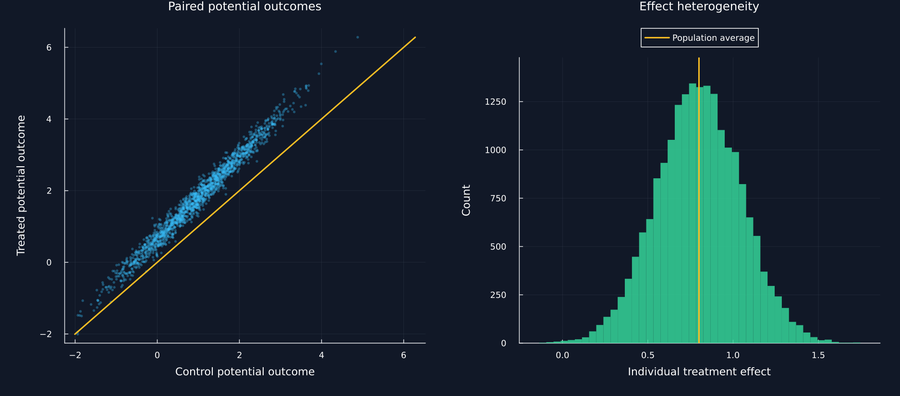

In [1]:
function table(values,name,caption)
    shown = copy(values)
    for column in names(shown)
        if all(value->value isa Bool,shown[!,column])
            shown[!,column] = ifelse.(shown[!,column],"Yes","No")
        end
    end
    save_table(shown,paths,name;caption,label="tab:chapter25-"*replace(name,"_"=>"-"))
    return nothing
end
function assert_artifacts(figures,tables)
    @assert all(name->isfile(joinpath(paths.figures,name*".pdf")),figures)
    @assert all(name->isfile(joinpath(paths.tables,name*".tex")),tables)
end
store = PrimitiveStore(input_directory,"average")
quickstart_effect = average_treatment_effect(3.5,1.25)
n_population = 20000
population_inputs = normal_block(store,"population")
covariate,control_shock = population_inputs[:,1],.8 .*population_inputs[:,2]
control_potential = 1.0 .+ .7 .*covariate+control_shock
individual_effect = .8 .+ .25 .*covariate
treated_potential = control_potential+individual_effect
true_ate = average_treatment_effect(mean(treated_potential),mean(control_potential))
potential_summary = frame(["Quantity","Value"],[("Quickstart treated mean",3.5),("Quickstart control mean",1.25),("Quickstart average effect",quickstart_effect),("Generated population average effect",true_ate),("Smallest individual effect",minimum(individual_effect)),("Largest individual effect",maximum(individual_effect))])
potential_moments = frame(["Potential outcome","Mean","Standard deviation"],[(name,mean(values),std(values)) for (name,values) in [("Control Y(0)",control_potential),("Treated Y(1)",treated_potential),("Individual effect",individual_effect)]])
table(potential_summary,"average_effect_quickstart","Exact and generated average-effect calculations.")
table(potential_moments,"potential_outcome_moments","Moments of the generated potential outcomes and individual effects.")
draw_index = floor.(Int,range(0,n_population-1;length=1600)).+1
scatter_panel = scatter(control_potential[draw_index],treated_potential[draw_index];markersize=2,markeralpha=.35,markerstrokewidth=0,color=palette.cyan,label="",xlabel="Control potential outcome",ylabel="Treated potential outcome",title="Paired potential outcomes")
limits = [min(minimum(control_potential[draw_index]),minimum(treated_potential[draw_index])),max(maximum(control_potential[draw_index]),maximum(treated_potential[draw_index]))]
plot!(scatter_panel,limits,limits;color=palette.amber,label="")
edges = collect(range(minimum(individual_effect),maximum(individual_effect);length=46))
effect_panel = histogram(individual_effect;bins=edges,color=palette.green,linealpha=0,alpha=.85,xlabel="Individual treatment effect",ylabel="Count",title="Effect heterogeneity",label="",ylims=(0,1.1histogram_peak(individual_effect,edges)),legend=:outertop)
vline!(effect_panel,[true_ate];color=palette.amber,label="Population average")
save_figure(plot(scatter_panel,effect_panel;layout=(1,2),size=(1250,550)),paths,"potential_outcomes_and_effects")
save_data(DataFrame("Population index"=>draw_index.-1,"Control potential outcome"=>control_potential[draw_index],"Treated potential outcome"=>treated_potential[draw_index]),paths,"potential_outcome_scatter");


## Recovering the effect by random assignment

Under random assignment, the sample contrast is:

$$
\widehat\tau_{\mathrm{DM}}
=\overline Y_{T=1}-\overline Y_{T=0}.
$$

Here, $T$ is the treatment indicator, $\overline Y_{T=1}$ is the mean observed outcome among treated units, $\overline Y_{T=0}$ is the mean observed outcome among control units, and $\widehat\tau_{\mathrm{DM}}$ is the difference-in-means estimate.

Row,Assignment,Treated share,Mean covariate among treated,Mean covariate among controls,Observed difference,Error from population ATE
,String,Float64,Float64,Float64,Float64,Float64
1,Random,0.49725,0.00625537,-0.00682809,0.806651,0.00673129
2,Selected by covariate,0.4622,0.470496,-0.404956,1.52764,0.727718


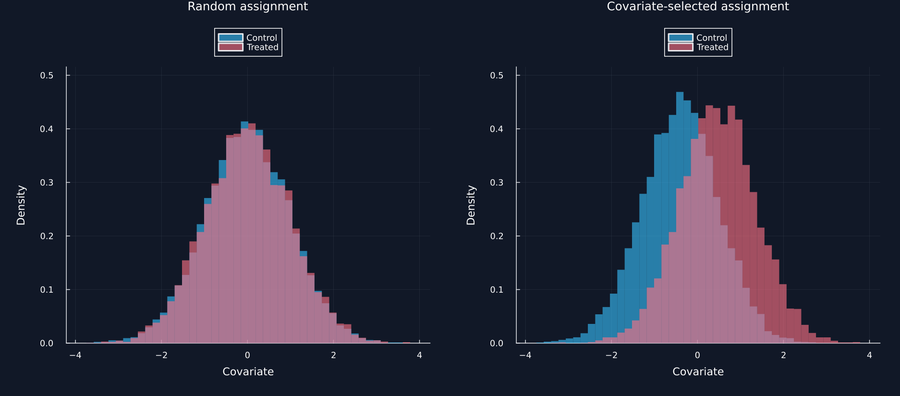

Row,Repetitions,Sample size,Mean estimate,Bias,Standard deviation,Root mean squared error,Middle 95 percent lower,Middle 95 percent upper
,Int64,Int64,Float64,Float64,Float64,Float64,Float64,Float64
1,500,600,0.803566,0.00364627,0.0947594,0.0947348,0.620168,0.98735


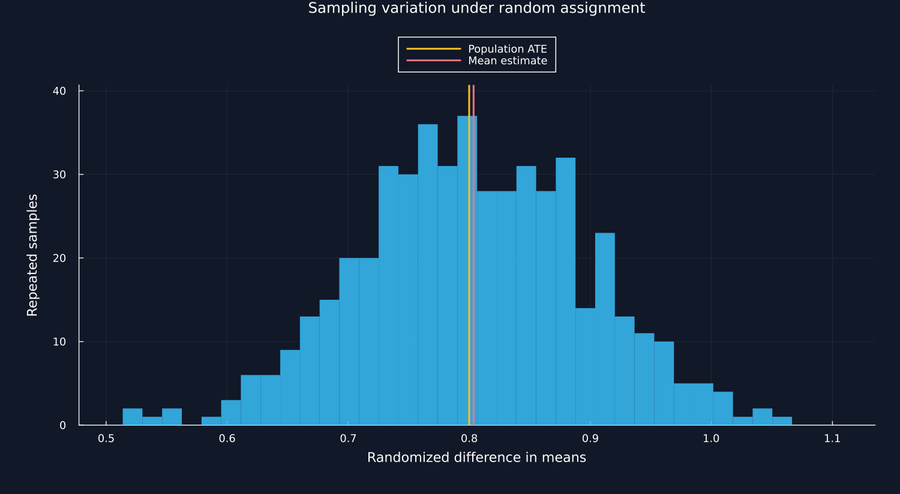

In [2]:
random_assignment = Int.(population_inputs[:,3])
selected_probability = 1.0 ./(1.0 .+exp.(-(-.2 .+ 1.1 .*covariate)))
selected_assignment = Int.(population_inputs[:,4])
observed_random = random_assignment.*treated_potential+(1 .-random_assignment).*control_potential
observed_selected = selected_assignment.*treated_potential+(1 .-selected_assignment).*control_potential
randomized_estimate = randomized_mean_difference(observed_random[random_assignment.==1],observed_random[random_assignment.==0])
selected_estimate = randomized_mean_difference(observed_selected[selected_assignment.==1],observed_selected[selected_assignment.==0])
assignment_comparison = frame(["Assignment","Treated share","Mean covariate among treated","Mean covariate among controls","Observed difference","Error from population ATE"],[(name,mean(assignment),mean(covariate[assignment.==1]),mean(covariate[assignment.==0]),estimate,estimate-true_ate) for (name,assignment,estimate) in [("Random",random_assignment,randomized_estimate),("Selected by covariate",selected_assignment,selected_estimate)]])
table(assignment_comparison,"assignment_comparison","Random and covariate-selected treatment assignments.")
bins = collect(range(minimum(covariate),maximum(covariate);length=45))
peak = maximum(histogram_peak(covariate[assignment.==value],bins;density=true) for assignment in [random_assignment,selected_assignment] for value in 0:1)
panels = Plots.Plot[]
for (assignment,title) in [(random_assignment,"Random assignment"),(selected_assignment,"Covariate-selected assignment")]
    panel = histogram(covariate[assignment.==0];bins,normalize=:pdf,color=palette.cyan,alpha=.62,linealpha=0,label="Control",xlabel="Covariate",ylabel="Density",title,ylims=(0,1.1peak),legend=:outertop)
    histogram!(panel,covariate[assignment.==1];bins,normalize=:pdf,color=palette.rose,alpha=.62,linealpha=0,label="Treated")
    push!(panels,panel)
end
save_figure(plot(panels...;layout=(1,2),size=(1250,550)),paths,"assignment_covariate_balance")
repetitions = 500
repetition_estimates = Float64[]
for repetition in 1:repetitions
    values = normal_block(store,"recovery",repetition)
    indices,assignment = Int.(values[:,1]).+1,Int.(values[:,2])
    outcomes = assignment.*treated_potential[indices]+(1 .-assignment).*control_potential[indices]
    push!(repetition_estimates,randomized_mean_difference(outcomes[assignment.==1],outcomes[assignment.==0]))
end
randomized_repetition_summary = frame(["Repetitions","Sample size","Mean estimate","Bias","Standard deviation","Root mean squared error","Middle 95 percent lower","Middle 95 percent upper"],[(repetitions,600,mean(repetition_estimates),mean(repetition_estimates)-true_ate,std(repetition_estimates),sqrt(mean(abs2,repetition_estimates.-true_ate)),quantile(repetition_estimates,.025),quantile(repetition_estimates,.975))])
table(randomized_repetition_summary,"randomized_repetition_summary","Repeated randomized differences in means.")
save_data(DataFrame("Repetition"=>0:repetitions-1,"Estimate"=>repetition_estimates),paths,"randomized_recovery_repetitions")
edges = collect(range(minimum(repetition_estimates),maximum(repetition_estimates);length=37))
figure = histogram(repetition_estimates;bins=edges,color=palette.cyan,alpha=.85,linealpha=0,label="",xlabel="Randomized difference in means",ylabel="Repeated samples",title="Sampling variation under random assignment",ylims=(0,1.1histogram_peak(repetition_estimates,edges)),legend=:outertop,size=(1000,550))
vline!(figure,[true_ate];color=palette.amber,label="Population ATE")
vline!(figure,[mean(repetition_estimates)];color=palette.rose,label="Mean estimate")
save_figure(figure,paths,"randomized_estimate_distribution")


## Precision as sample size grows

Repeated-sample bias and root mean squared error are measured by:

$$
\widehat B_R=\frac{1}{R}\sum_{r=1}^{R}(\widehat\tau_r-\tau),
\qquad
\widehat{\operatorname{RMSE}}_R
=\sqrt{\frac{1}{R}\sum_{r=1}^{R}(\widehat\tau_r-\tau)^2}.
$$

Here, $R$ is the number of repeated samples, $r$ labels one sample, $\widehat\tau_r$ is its estimated effect, $\tau$ is the known population effect, $\widehat B_R$ is estimated bias, and $\widehat{\operatorname{RMSE}}_R$ is estimated root mean squared error.

Row,Sample size,Mean estimate,Bias,Standard deviation,Root mean squared error
,Int64,Float64,Float64,Float64,Float64
1,50,0.816066,0.0161471,0.31797,0.317926
2,100,0.80402,0.00410018,0.233831,0.233532
3,250,0.820442,0.0205228,0.153787,0.154932
4,500,0.796342,-0.00357766,0.104062,0.103975
5,1000,0.801753,0.00183311,0.0738702,0.0737874
6,2500,0.799194,-0.000725146,0.0451153,0.0450567


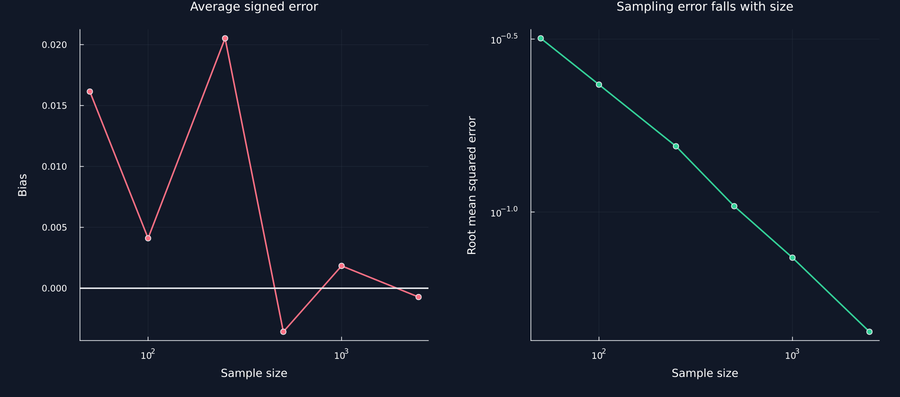

In [3]:
sample_sizes = [50,100,250,500,1000,2500]
size_rows,size_repetitions = Tuple[],Tuple[]
for sample_size in sample_sizes
    estimates = Float64[]
    for repetition in 1:350
        values = normal_block(store,"size_"*string(sample_size),repetition)
        indices,assignment = Int.(values[:,1]).+1,Int.(values[:,2])
        outcomes = assignment.*treated_potential[indices]+(1 .-assignment).*control_potential[indices]
        estimate = randomized_mean_difference(outcomes[assignment.==1],outcomes[assignment.==0])
        push!(estimates,estimate)
        push!(size_repetitions,(sample_size,repetition-1,estimate))
    end
    push!(size_rows,(sample_size,mean(estimates),mean(estimates)-true_ate,std(estimates),sqrt(mean(abs2,estimates.-true_ate))))
end
randomized_sample_size = frame(["Sample size","Mean estimate","Bias","Standard deviation","Root mean squared error"],size_rows)
table(randomized_sample_size,"randomized_sample_size","Randomized-estimator behavior as sample size grows.")
save_data(frame(["Sample size","Repetition","Estimate"],size_repetitions),paths,"randomized_size_repetitions")
bias_panel = plot(randomized_sample_size[!,"Sample size"],randomized_sample_size.Bias;marker=:circle,color=palette.rose,xscale=:log10,xlabel="Sample size",ylabel="Bias",title="Average signed error",label="")
hline!(bias_panel,[0];color=palette.text,label="")
error_panel = plot(randomized_sample_size[!,"Sample size"],randomized_sample_size[!,"Root mean squared error"];marker=:circle,color=palette.green,xscale=:log10,yscale=:log10,xlabel="Sample size",ylabel="Root mean squared error",title="Sampling error falls with size",label="")
save_figure(plot(bias_panel,error_panel;layout=(1,2),size=(1200,530)),paths,"randomized_sample_size_behavior")


## How selection enters the observed difference

The treated-versus-control difference can be separated as follows:

$$
\mathbb E[Y\mid T=1]-\mathbb E[Y\mid T=0]
=\mathbb E[Y(1)-Y(0)\mid T=1]
+\left\{\mathbb E[Y(0)\mid T=1]-\mathbb E[Y(0)\mid T=0]\right\}.
$$

Here, $T$ is treatment status, the first term on the right is the average treatment effect among treated units, the bracketed term is selection bias in the untreated potential outcome, and consistency connects the observed treated outcome to $Y(1)$ for treated units.

Row,Component,Value
,String,Float64
1,Observed difference,1.52764
2,Effect among treated,0.917624
3,Selection bias,0.610013
4,Sum of effect and selection,1.52764


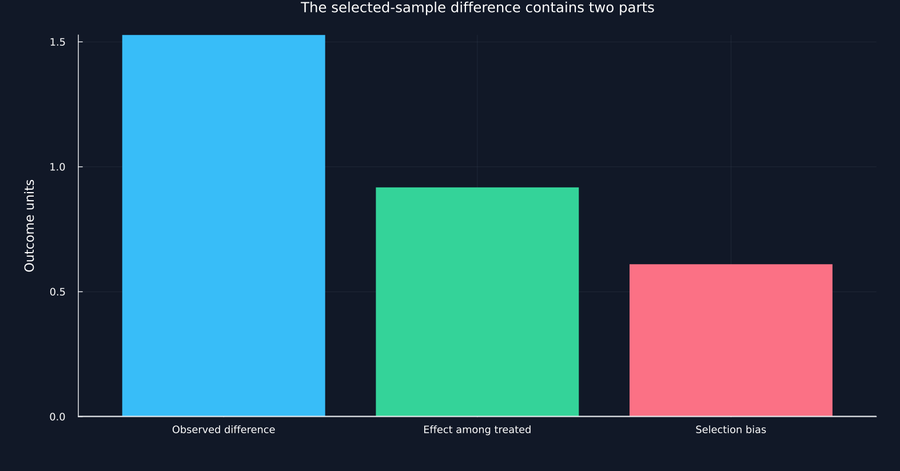

In [4]:
observed_treated_mean = mean(observed_selected[selected_assignment.==1])
observed_control_mean = mean(observed_selected[selected_assignment.==0])
counterfactual_control_treated = mean(control_potential[selected_assignment.==1])
decomposition = treatment_effect_decomposition(observed_treated_mean,observed_control_mean,counterfactual_control_treated)
decomposition_table = frame(["Component","Value"],[("Observed difference",decomposition.observed_difference),("Effect among treated",decomposition.average_treatment_effect_on_treated),("Selection bias",decomposition.sample_selection_bias),("Sum of effect and selection",decomposition.average_treatment_effect_on_treated+decomposition.sample_selection_bias)])
table(decomposition_table,"selection_decomposition","Observed difference separated into effect among treated and selection bias.")
figure = bar(1:3,decomposition_table.Value[1:3];color=[palette.cyan,palette.green,palette.rose],linealpha=0,xticks=(1:3,["Observed difference","Effect among treated","Selection bias"]),ylabel="Outcome units",title="The selected-sample difference contains two parts",legend=false,size=(1050,550))
hline!(figure,[0];color=palette.text,label="")
save_figure(figure,paths,"selection_decomposition")


## Adjustment by standardization

A standardized effect averages within-group contrasts over a common adjustment distribution:

$$
\tau_{\mathrm{adj}}
=\sum_{s}\left\{\mathbb E[Y\mid T=1,S=s]-\mathbb E[Y\mid T=0,S=s]\right\}P(S=s).
$$

Here, $S$ is a valid adjustment variable, $s$ labels one of its groups, $P(S=s)$ is that group's population share, and $\tau_{\mathrm{adj}}$ is the standardized average contrast.

Row,Stratum,Population share,Treated count,Control count,Treated mean,Control mean,Within-stratum contrast
,Int64,Float64,Int64,Int64,Float64,Float64,Float64
1,1,0.1,231,1769,0.256914,-0.236618,0.493532
2,2,0.1,416,1584,0.858465,0.266037,0.592428
3,3,0.1,583,1417,1.14481,0.549928,0.594885
4,4,0.1,713,1287,1.44452,0.713709,0.730809
5,5,0.1,796,1204,1.67968,0.9559,0.72378
6,6,0.1,978,1022,1.8853,1.02392,0.861375
7,7,0.1,1112,888,2.21844,1.3016,0.916836
8,8,0.1,1285,715,2.47082,1.44079,1.03003
9,9,0.1,1432,568,2.75072,1.73843,1.01229


Row,Quantity,Value
,String,Float64
1,Population ATE,0.799919
2,Selected observed difference,1.52764
3,Ten-stratum adjusted effect,0.831107
4,Standardized treated mean,1.81658
5,Standardized control mean,0.985472
6,Two-stratum expectation check,0.275
7,Two-stratum effect check,0.4


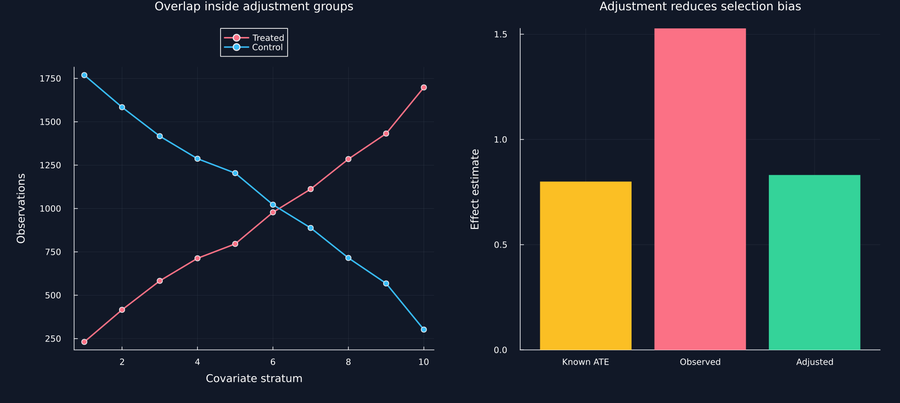

In [5]:
stratum_edges = unique(quantile(covariate,collect(0:.1:1)))
strata = [max(1,searchsortedfirst(stratum_edges,value)-1) for value in covariate]
stratum_rows = Tuple[]
treated_means,control_means,weights = Float64[],Float64[],Float64[]
for stratum in sort(unique(strata))
    member = strata.==stratum
    treated_member,control_member = member .& (selected_assignment.==1),member .& (selected_assignment.==0)
    treated_mean,control_mean,weight = mean(observed_selected[treated_member]),mean(observed_selected[control_member]),mean(member)
    push!(treated_means,treated_mean)
    push!(control_means,control_mean)
    push!(weights,weight)
    push!(stratum_rows,(stratum,weight,sum(treated_member),sum(control_member),treated_mean,control_mean,treated_mean-control_mean))
end
standardization_inputs = frame(["Stratum","Population share","Treated count","Control count","Treated mean","Control mean","Within-stratum contrast"],stratum_rows)
adjusted_effect = backdoor_adjusted_average_treatment_effect(treated_means,control_means,weights)
standardized_treated = backdoor_adjusted_expectation(treated_means,weights)
standardized_control = backdoor_adjusted_expectation(control_means,weights)
hand_expectation = backdoor_adjusted_expectation([.1,.8],[.75,.25])
hand_effect = backdoor_adjusted_average_treatment_effect([.4,.9],[.1,.2],[.75,.25])
adjustment_comparison = frame(["Quantity","Value"],[("Population ATE",true_ate),("Selected observed difference",selected_estimate),("Ten-stratum adjusted effect",adjusted_effect),("Standardized treated mean",standardized_treated),("Standardized control mean",standardized_control),("Two-stratum expectation check",hand_expectation),("Two-stratum effect check",hand_effect)])
table(standardization_inputs,"standardization_inputs","Inputs to the ten-group standardization calculation.")
table(adjustment_comparison,"adjustment_comparison","Observed, adjusted, and known treatment-effect quantities.")
save_data(DataFrame("Covariate"=>covariate,"Control potential"=>control_potential,"Treated potential"=>treated_potential,"Individual effect"=>individual_effect,"Random assignment"=>random_assignment,"Selected probability"=>selected_probability,"Selected assignment"=>selected_assignment,"Random observed"=>observed_random,"Selected observed"=>observed_selected,"Stratum"=>strata),paths,"potential_outcome_population")
overlap_panel = plot(standardization_inputs.Stratum,standardization_inputs[!,"Treated count"];marker=:circle,color=palette.rose,label="Treated",xlabel="Covariate stratum",ylabel="Observations",title="Overlap inside adjustment groups",legend=:outertop)
plot!(overlap_panel,standardization_inputs.Stratum,standardization_inputs[!,"Control count"];marker=:circle,color=palette.cyan,label="Control")
effect_panel = bar(1:3,[true_ate,selected_estimate,adjusted_effect];color=[palette.amber,palette.rose,palette.green],linealpha=0,xticks=(1:3,["Known ATE","Observed","Adjusted"]),ylabel="Effect estimate",title="Adjustment reduces selection bias",legend=false)
save_figure(plot(overlap_panel,effect_panel;layout=(1,2),size=(1250,560)),paths,"standardization_overlap_and_effect")


## A discrete front-door calculation

The discrete front-door formula used by the public calculation is:

$$
P(y\mid\operatorname{do}(x))
=\sum_m P(m\mid x)\sum_{x'}P(y\mid m,x')P(x').
$$

Here, $x$ is the treatment value set by intervention, $m$ indexes mediator states, $x'$ indexes observed treatment states, $P(m\mid x)$ gives the mediator distribution under the chosen treatment, and $P(y\mid m,x')$ gives the conditional chance of one fixed outcome event.

In [6]:
mediator_probabilities,outcome_probabilities,treatment_probabilities = [.25,.75],[.1 .5;.4 .8],[.6,.4]
frontdoor_probability = frontdoor_adjusted_probability(mediator_probabilities,outcome_probabilities,treatment_probabilities)
inner_values = outcome_probabilities*treatment_probabilities
frontdoor_hand = frame(["Mediator state","Mediator weight","Inner outcome average","Contribution"],[(index-1,mediator_probabilities[index],inner_values[index],mediator_probabilities[index]*inner_values[index]) for index in 1:2])
frontdoor_total = frame(["Calculation","Probability"],[("Sum of contributions",sum(frontdoor_hand.Contribution)),("Public function",frontdoor_probability)])
table(frontdoor_hand,"frontdoor_probability_components","Components of the discrete front-door probability.")
table(frontdoor_total,"frontdoor_probability_total","Hand and public front-door probability calculations.")
input_checks = frame(["Check","Expected result","Observed result","Passed"],[contract_result("Boolean average-effect input",()->average_treatment_effect(true,0.),ArgumentError),contract_result("Empty randomized group",()->randomized_mean_difference(Float64[],[1.]),ArgumentError),contract_result("Mismatched adjustment lengths",()->backdoor_adjusted_expectation([1.],[.4,.6]),ArgumentError),contract_result("Weights do not sum to one",()->backdoor_adjusted_expectation([1.,2.],[.4,.4]),ArgumentError),contract_result("Invalid front-door probability",()->frontdoor_adjusted_probability([1.],reshape([1.2],1,1),[1.]),ArgumentError),contract_result("Zero instrument denominator",()->linear_instrumental_variable_effect(1.,0.),ArgumentError)])
section_summary = frame(["Question","Answer"],[["What does random assignment protect?","It balances potential outcomes in expectation"],["What can an observed difference contain?","A treatment effect and selection bias"],["What does standardization require?","A valid adjustment set and overlap"],["Does a formula prove its assumptions?","No"]])
table(input_checks,"treatment_effect_input_checks","Input checks for the public treatment-effect calculations.")
table(section_summary,"average_effect_section_summary","Main conclusions from the average-effect experiments.")


Row,Mediator state,Mediator weight,Inner outcome average,Contribution
,Int64,Float64,Float64,Float64
1,0,0.25,0.26,0.065
2,1,0.75,0.56,0.42


Row,Calculation,Probability
,String,Float64
1,Sum of contributions,0.485
2,Public function,0.485


Row,Check,Expected result,Observed result,Passed
,String,String,String,String
1,Boolean average-effect input,Rejected,Rejected,Yes
2,Empty randomized group,Rejected,Rejected,Yes
3,Mismatched adjustment lengths,Rejected,Rejected,Yes
4,Weights do not sum to one,Rejected,Rejected,Yes
5,Invalid front-door probability,Rejected,Rejected,Yes
6,Zero instrument denominator,Rejected,Rejected,Yes


Row,Question,Answer
,String,String
1,What does random assignment protect?,It balances potential outcomes in expectation
2,What can an observed difference contain?,A treatment effect and selection bias
3,What does standardization require?,A valid adjustment set and overlap
4,Does a formula prove its assumptions?,No


## Tests

In [7]:
@assert quickstart_effect==2.25
@assert abs(randomized_estimate-true_ate)<.06
@assert abs(selected_estimate-true_ate)>.35
@assert decomposition.observed_difference==decomposition.average_treatment_effect_on_treated+decomposition.sample_selection_bias
@assert abs(adjusted_effect-true_ate)<abs(selected_estimate-true_ate)
@assert randomized_sample_size[end,"Root mean squared error"]<randomized_sample_size[1,"Root mean squared error"]
@assert hand_expectation≈.275
@assert hand_effect≈.4
@assert frontdoor_probability≈.485
@assert all(input_checks.Passed)
assert_artifacts(["potential_outcomes_and_effects","assignment_covariate_balance","randomized_estimate_distribution","randomized_sample_size_behavior","selection_decomposition","standardization_overlap_and_effect"],["average_effect_quickstart","potential_outcome_moments","assignment_comparison","randomized_repetition_summary","randomized_sample_size","selection_decomposition","standardization_inputs","adjustment_comparison","frontdoor_probability_components","frontdoor_probability_total","treatment_effect_input_checks","average_effect_section_summary"])
nothing
